In [1]:
import torch
from rex_xai.lib import ReX
import sys, pickle, warnings
from pathlib import Path
import numpy as np
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from PIL import Image
from rex_xai.responsibility.prediction import from_pytorch_tensor

In [2]:
# SETUP
ROOT = Path.cwd().parent
DATA = ROOT / "data"
sys.path.insert(0, str(ROOT / "ConceptBottleneck"))
warnings.filterwarnings("ignore", message="source code of class")

# Setup CUDA device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, torch.cuda.get_device_name(0) if device == "cuda" else "")

# Open Dataset
test_data = pickle.load(open(DATA / "CUB_processed/test.pkl", "rb"))

# Name of the classes
classes = open(DATA / "CUB_200_2011/classes.txt").read().splitlines()
print(f"Classes example: {classes[::15][:5]}")

# Load models
joint_model_path = DATA / "models" / "Joint0.01Model__Seed1" / "best_model_1.pth"
joint_model = torch.load(joint_model_path, map_location=torch.device(device), weights_only=False)
joint_model.eval()

concept_model_path = DATA / "models" / "ConceptModel__Seed1" / "best_model_1.pth"
concept_model = torch.load(concept_model_path, map_location=torch.device(device), weights_only=False)
concept_model.eval()

independent_head_path = DATA / "models" / "IndependentModel_WithVal___Seed1" / "best_model_1.pth"
independent_head = torch.load(independent_head_path, map_location=torch.device(device), weights_only=False)
independent_head.eval()

sequential_head_path = DATA / "models" / "SequentialModel_WithVal__Seed1" / "best_model_1.pth"
sequential_head = torch.load(sequential_head_path, map_location=torch.device(device), weights_only=False)
sequential_head.eval()

cuda NVIDIA GeForce RTX 4070 Laptop GPU
Classes example: ['1 001.Black_footed_Albatross', '16 016.Painted_Bunting', '31 031.Black_billed_Cuckoo', '46 046.Gadwall', '61 061.Heermann_Gull']


MLP(
  (linear): Linear(in_features=112, out_features=200, bias=True)
)

In [3]:
resol = 299
model_shape = ["N", 3, resol, resol]


# Helpers
def crop_image(img, resol):
    transform = transforms.Compose([
        transforms.CenterCrop(resol)
    ])

    return transform(img)

def to_tensor(img):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean = [0.5, 0.5, 0.5], std = [2, 2, 2])
    ])

    return transform(img)

def get_image_path_from_index(index, dataset=test_data):
    img_path = DATA / "CUB_200_2011" / dataset[index]["img_path"].split("CUB_200_2011/")[-1]
    return str(img_path)


def get_bird_mask(index, resol=299):
    segmentation_path = Path(get_image_path_from_index(index).replace("/images/", "/segmentations/")).with_suffix(".png")
    seg_img = Image.open(segmentation_path).convert("L")
    cropped_seg_img = crop_image(seg_img, resol)

    cropped_tensor = torch.from_numpy(np.array(cropped_seg_img))

    return (cropped_tensor > 127).to(device)

def get_class_name(class_idx):
    return classes[class_idx].strip().split(" ")[1]

def get_class_from_index(index, dataset=test_data):
    return get_class_name(dataset[index]["class_label"])

def joint_prediction_function(mutants, target=None, raw=False):
    with torch.no_grad():
        class_logits = joint_model(mutants)[0]

    if raw:
        return torch.softmax(class_logits, dim=1)
    else:
        return from_pytorch_tensor(class_logits, target=target)
    

def setup_rex(index, model, model_shape, prediction_function, resol=299):

    rex = ReX(model, model_shape, device, "RGB", prediction_function)
    image_path = get_image_path_from_index(index, test_data)
    image = rex.set_rgb_image(image_path)
    cropped_img  = crop_image(image, resol)
    
    rex.set_input(cropped_img)
    transformed_img = to_tensor(cropped_img).unsqueeze(0).to(device)
    rex.set_transformed_data(transformed_img)
    rex.set_target()

    return rex, cropped_img


def run_rex_seeds(rex, seeds, threshold=0.0):
    masks = {}
    stats = {}
    rex.args.minimum_confidence_threshold = threshold

    for seed in seeds:
        rex.args.seed = seed
        rex.calculate_responsibility().generate_explanation_object()
        stats[seed] = dict(rex.stats)
        rex.extract_sufficient_explanation()

        mask = rex.explanation.sufficiency_mask
        assert (mask[0] == mask[1]).all() and (mask[0] == mask[2]).all()  # all 3 channels identical
        masks[seed] = mask[0].clone()                                      # keep one [299, 299] channel

    return masks, stats


get_class_from_index(10)

'001.Black_footed_Albatross'

In [ ]:
idx = 10
rex, cropped_img = setup_rex(idx, joint_model, model_shape, joint_prediction_function)
rex.show_target()
masks, stats = run_rex_seeds(rex, range(3))
for seed in masks:
    print(seed, stats[seed], f"{masks[seed].float().mean().item():.1%}")

FOUND_CLASS: 0, FOUND_CONF: 0.99987, TARGET_CLASS: n/a, TARGET_CONFIDENCE: n/a


Extracting global explanation:  23%|██▎       | 2098/8940 [00:15<00:48, 139.69it/s]

0 {'total_passing': 494, 'total_failing': 1284, 'max_depth_reached': 6, 'avg_box_size': 4777.25625} 25.4%
1 {'total_passing': 484, 'total_failing': 1280, 'max_depth_reached': 6, 'avg_box_size': 4855.931250000001} 25.8%
2 {'total_passing': 489, 'total_failing': 1289, 'max_depth_reached': 6, 'avg_box_size': 4742.06875} 23.5%


In [5]:
def bird_share(explanation, bird):
    share = (explanation & bird).sum() / explanation.sum()
    size = explanation.float().mean().item()

    return size, share.item()

def predict_keeping_pixels(rex, keep_mask, prediction_function):
    """Keep only pixels where keep_mask is True (rest -> 0, mid-grey).
    Returns (top class, top class probability, original target's probability)."""
    masked_input = rex.data.data * keep_mask.float().to(device)
    probs = prediction_function(masked_input, raw=True)          # [1, 200]
    
    top_conf, top_class = torch.max(probs, dim=1)     # most likely class now
    target = rex.data.target.classification           # class ReX explained (int)
    target_conf = probs[0, target].item()             # how likely that class still is
    
    return top_class.item(), top_conf.item(), target_conf

def keeping_test(rex, masks, bird, prediction_function):
    rows = []

    for seed, explanation in masks.items():
        green = explanation & bird
        red = explanation & ~bird

        for name, keep in [("full", explanation), ("green", green), ("red", red)]:
            top_class, top_conf, target_conf = predict_keeping_pixels(rex, keep, prediction_function)
            size = keep.float().mean().item()
            rows.append({"seed": seed, "kept": name, "size": size,
                        "top_class": get_class_name(top_class),
                        "top_conf": top_conf, "target_conf": target_conf})
            
            print(f"seed {seed} | {name:5} | {size:.1%} | {get_class_name(top_class)} {top_conf:.3f} | target {target_conf:.2e}")
        print()

    return rows


bird = get_bird_mask(idx)
rows = keeping_test(rex, masks, bird, joint_prediction_function)

seed 0 | full  | 25.4% | 001.Black_footed_Albatross 0.090 | target 8.99e-02
seed 0 | green | 11.3% | 135.Bank_Swallow 0.290 | target 2.63e-04
seed 0 | red   | 14.1% | 030.Fish_Crow 0.451 | target 3.54e-04

seed 1 | full  | 25.8% | 001.Black_footed_Albatross 0.126 | target 1.26e-01
seed 1 | green | 11.5% | 137.Cliff_Swallow 0.296 | target 3.35e-04
seed 1 | red   | 14.3% | 023.Brandt_Cormorant 0.368 | target 7.83e-04

seed 2 | full  | 23.5% | 001.Black_footed_Albatross 0.122 | target 1.22e-01
seed 2 | green | 9.6% | 135.Bank_Swallow 0.304 | target 2.49e-04
seed 2 | red   | 13.8% | 030.Fish_Crow 0.495 | target 4.69e-04



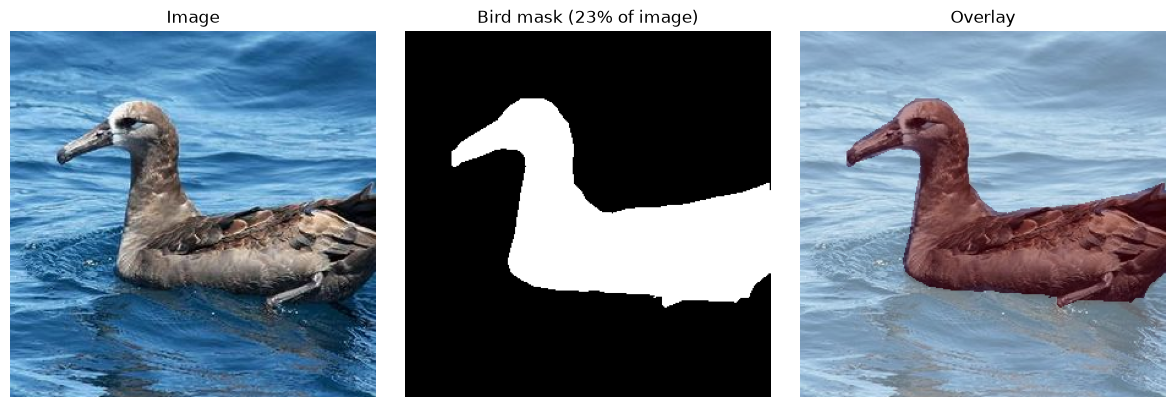

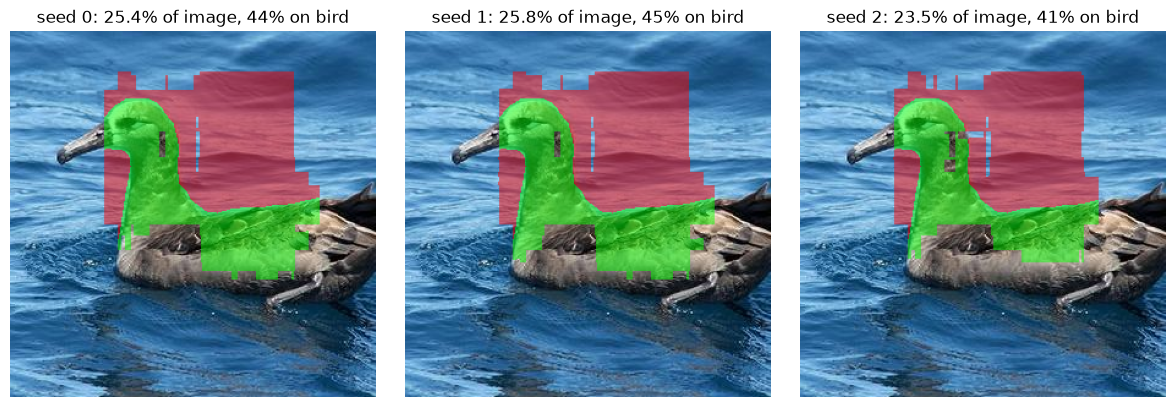

In [6]:
def plot_img_and_seg(img, bird, save_path=None):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    #cropped image
    axes[0].imshow(img)

    # Masked Image
    bird_np = bird.cpu().numpy()
    axes[1].imshow(bird_np, cmap="gray")

    # Cropped image with mask on top
    axes[2].imshow(img)
    axes[2].imshow(bird_np, alpha=0.4, cmap="Reds")

    titles = ["Image", f"Bird mask ({bird.float().mean().item():.0%} of image)", "Overlay"]
    for axis, title in zip(axes, titles):
        axis.set_title(title) 
        axis.axis("off")

    plt.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")

    plt.show()


def plot_seed_overlays(img, bird, masks, save_path=None):
    seeds = list(masks.keys())
    fig, axes = plt.subplots(1, len(seeds), figsize=(4 * len(seeds), 4))
    axes = np.atleast_1d(axes)                        # works for 1 seed too
    bird_np = bird.cpu().numpy()                      # GPU tensor → numpy, as before

    for axis, seed in zip(axes, seeds):
        explanation = masks[seed].cpu().numpy()  
        
        on = explanation & bird_np    # explanation pixels that are bird
        off = explanation & ~bird_np  # explanation pixels that are not bird
        
        overlay = np.zeros((*explanation.shape, 4))   # RGBA layer
        overlay[on] = [0, 1, 0, 0.5]   # green
        overlay[off] = [1, 0, 0, 0.5]  # red

        # fraction of the image the explanation covers
        # fraction of the explanation on the bird
        size, share = bird_share(masks[seed], bird)
        
        axis.imshow(img)
        axis.imshow(overlay)
        axis.set_title(f"seed {seed}: {size:.1%} of image, {share:.0%} on bird")
        axis.axis("off")

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

plot_img_and_seg(cropped_img, bird)
plot_seed_overlays(cropped_img, bird, masks)

Extracting global explanation:  32%|███▏      | 2901/8940 [00:22<00:46, 130.99it/s]


0 {'total_passing': 494, 'total_failing': 1284, 'max_depth_reached': 6, 'avg_box_size': 4777.25625} 31.8% of image, 45% on bird
1 {'total_passing': 484, 'total_failing': 1280, 'max_depth_reached': 6, 'avg_box_size': 4855.931250000001} 32.4% of image, 45% on bird
2 {'total_passing': 489, 'total_failing': 1289, 'max_depth_reached': 6, 'avg_box_size': 4742.06875} 32.4% of image, 44% on bird


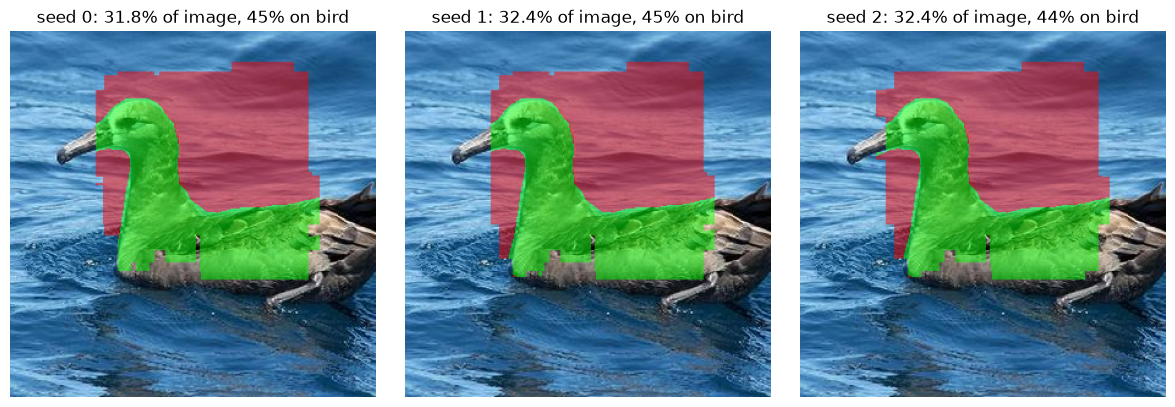

seed 0 | full  | 31.8% | 001.Black_footed_Albatross 0.903 | target 9.03e-01
seed 0 | green | 14.5% | 138.Tree_Swallow 0.117 | target 8.12e-04
seed 0 | red   | 17.3% | 008.Rhinoceros_Auklet 0.349 | target 2.50e-02

seed 1 | full  | 32.4% | 001.Black_footed_Albatross 0.901 | target 9.01e-01
seed 1 | green | 14.6% | 138.Tree_Swallow 0.175 | target 5.88e-04
seed 1 | red   | 17.8% | 008.Rhinoceros_Auklet 0.333 | target 4.24e-02

seed 2 | full  | 32.4% | 001.Black_footed_Albatross 0.905 | target 9.05e-01
seed 2 | green | 14.4% | 142.Black_Tern 0.218 | target 1.17e-03
seed 2 | red   | 18.1% | 008.Rhinoceros_Auklet 0.326 | target 6.20e-02



In [7]:
threshold = 0.9
masks_t, stats_t = run_rex_seeds(rex, range(3), threshold=threshold)
for seed in masks_t:
    size, share = bird_share(masks_t[seed], bird)
    print(seed, stats_t[seed], f"{size:.1%} of image, {share:.0%} on bird")

plot_seed_overlays(cropped_img, bird, masks_t)
rows_t = keeping_test(rex, masks_t, bird, joint_prediction_function)

In [8]:
def control_images(rex, bird, prediction_function, verbose=False):
    just_bird = predict_keeping_pixels(rex, bird, prediction_function)
    remove_bird = predict_keeping_pixels(rex, ~bird, prediction_function)

    if verbose:
        print("Just Bird Image")
        print(f" Top: {get_class_name(just_bird[0])} {just_bird[1]:.3f} | target prob {just_bird[2]:.2e}\n")

        print("Remove Bird Image")
        print(f" Top: {get_class_name(remove_bird[0])} {remove_bird[1]:.3f} | target prob {remove_bird[2]:.2e}\n")

    return just_bird, remove_bird


## Findings: image 10 (Black-footed Albatross), Joint model

**Setup:** ReX, seeds 0–2, mask value 0 (grey), 299 crop. Bird mask from CUB segmentation (> 127). Bird = 23% of the image.

**1. Explanations are stable across seeds.** Same region every time: head, neck, front of back, plus a block of water above the back. Bill and rear body left out.

**2. Default threshold (0.0) is too weak.**

| | Threshold 0.0 | Threshold 0.9 |
|---|---|---|
| Explanation size | 23–26% of image | 32% of image |
| On bird | 41–45% | 44–45% |
| Albatross confidence (explanation only) | 0.09–0.13 | 0.90 |

ReX stats are identical at both thresholds: the threshold only changes how many pixels are kept, not the ranking. **Decision: use threshold 0.9.**

**3. The explanation needs both bird and water (threshold 0.9).**

| Kept | Top class | Albatross prob. |
|---|---|---|
| Full explanation | Albatross 0.90 | 0.90 |
| Bird part only | Tree Swallow / Black Tern | ~0.001 |
| Water part only | Rhinoceros Auklet | 0.03–0.06 |

**4. Controls.**

| Kept | Top class | Albatross prob. |
|---|---|---|
| Whole image | Albatross | 0.9999 |
| Whole bird only | Albatross | 0.42 |
| Everything except bird | Northern Fulmar | 0.05 |

**Takeaway:** the bird alone is enough but with low confidence; the background alone points to "seabird on water". Together they give near-certain confidence, so the model uses context. In the Joint CBM the class is computed only from the concepts, so the background must be influencing the concept predictions. Check this next by looking at the concept outputs on the masked images.

**Caveats:** one image, one model. Grey cut-outs are unnatural inputs. The segmentation outline is rough at the bird/water border.


In [9]:
def run_image(idx, threshold=0.9, seeds=range(3), prediction_function=joint_prediction_function, model=joint_model):
    # 1. Set up ReX and check the prediction
    rex, cropped_img = setup_rex(idx, model, model_shape, prediction_function)
    true_class = get_class_from_index(idx)
    pred_class = get_class_name(rex.data.target.classification)
    correct = pred_class == true_class                              # True if pred and true match
    print(f"idx {idx} | true: {true_class} | predicted: {pred_class} "
        f"({rex.data.target.confidence:.3f}) | {'CORRECT' if correct else 'WRONG'}")

    # 2. Bird mask
    bird = get_bird_mask(idx)
    plot_img_and_seg(cropped_img, bird)

    # 3. ReX explanations
    masks, stats = run_rex_seeds(rex, seeds, threshold)
    shares = {}
    for seed in masks:
        size, share = bird_share(masks[seed], bird)
        shares[seed] = (size, share)
        print(f"seed {seed} | {size:.1%} of image | {share:.0%} on bird")
    plot_seed_overlays(cropped_img, bird, masks)

    # 4. Keeping test and controls
    rows = keeping_test(rex, masks, bird, prediction_function)
    controls = control_images(rex, bird, prediction_function, verbose=True)

    return {"idx": idx, "true": true_class, "pred": pred_class, "correct": correct,
            "bird_size": bird.float().mean().item(),
            "masks": masks, "stats": stats, "shares": shares,
            "rows": rows, "controls": controls}

idx 40 | true: 002.Laysan_Albatross | predicted: 002.Laysan_Albatross (0.999) | CORRECT


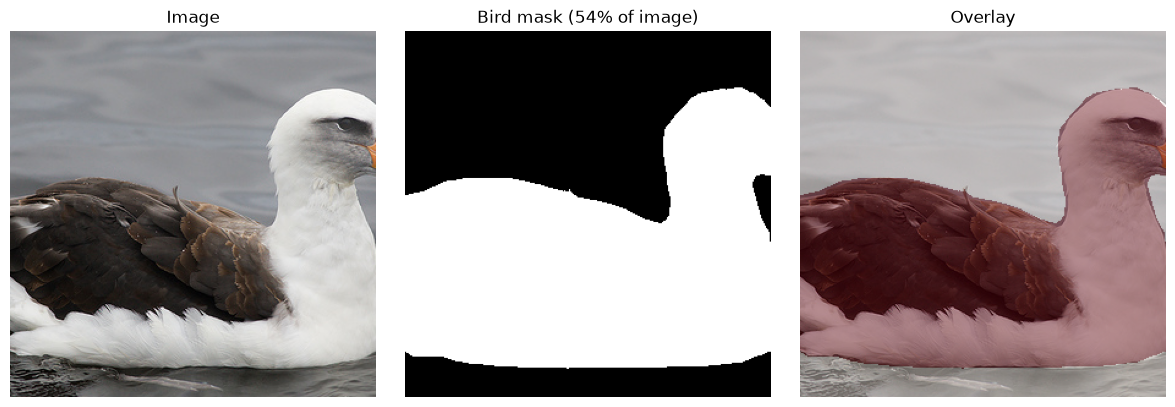

Extracting global explanation:  58%|█████▊    | 5187/8940 [00:38<00:27, 136.11it/s]


seed 0 | 58.0% of image | 68% on bird


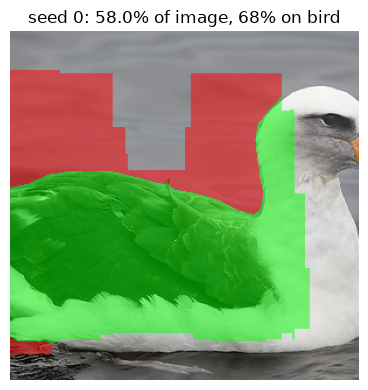

seed 0 | full  | 58.0% | 002.Laysan_Albatross 0.902 | target 9.02e-01
seed 0 | green | 39.4% | 002.Laysan_Albatross 0.967 | target 9.67e-01
seed 0 | red   | 18.7% | 063.Ivory_Gull 0.187 | target 1.53e-02

Just Bird Image
 Top: 002.Laysan_Albatross 0.996 | target prob 9.96e-01

Remove Bird Image
 Top: 063.Ivory_Gull 0.291 | target prob 2.91e-02

idx 3000 | true: 106.Horned_Puffin | predicted: 106.Horned_Puffin (0.989) | CORRECT


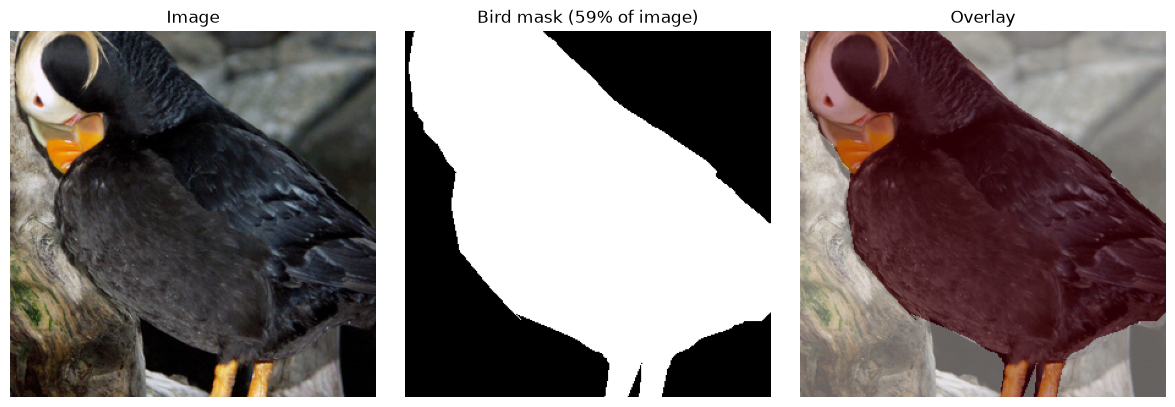

Extracting global explanation:   1%|▏         | 134/8940 [00:00<01:04, 137.49it/s]


seed 0 | 1.5% of image | 100% on bird


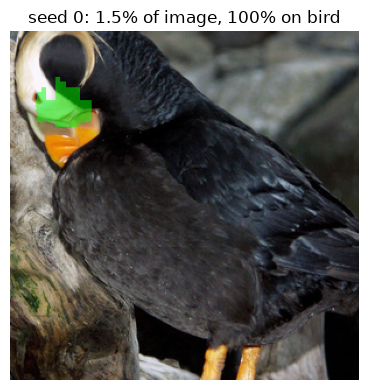

seed 0 | full  | 1.5% | 106.Horned_Puffin 0.907 | target 9.07e-01
seed 0 | green | 1.5% | 106.Horned_Puffin 0.907 | target 9.07e-01
seed 0 | red   | 0.0% | 045.Northern_Fulmar 0.208 | target 3.57e-03

Just Bird Image
 Top: 106.Horned_Puffin 0.988 | target prob 9.88e-01

Remove Bird Image
 Top: 099.Ovenbird 0.088 | target prob 6.43e-02

idx 1500 | true: 054.Blue_Grosbeak | predicted: 054.Blue_Grosbeak (0.894) | CORRECT


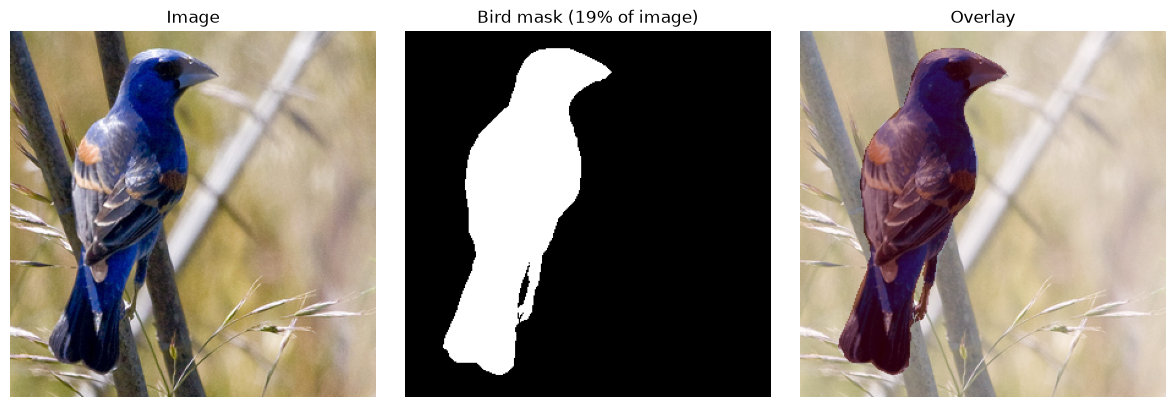

Extracting global explanation:  33%|███▎      | 2936/8940 [00:22<00:45, 131.35it/s]


seed 0 | 32.8% of image | 40% on bird


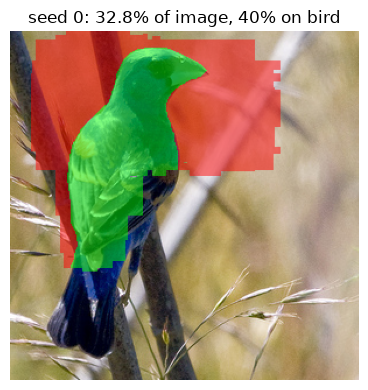

seed 0 | full  | 32.8% | 054.Blue_Grosbeak 0.805 | target 8.05e-01
seed 0 | green | 13.2% | 054.Blue_Grosbeak 0.803 | target 8.03e-01
seed 0 | red   | 19.6% | 014.Indigo_Bunting 0.075 | target 5.28e-03

Just Bird Image
 Top: 054.Blue_Grosbeak 0.968 | target prob 9.68e-01

Remove Bird Image
 Top: 156.White_eyed_Vireo 0.168 | target prob 1.07e-04

idx 5500 | true: 191.Red_headed_Woodpecker | predicted: 191.Red_headed_Woodpecker (0.999) | CORRECT


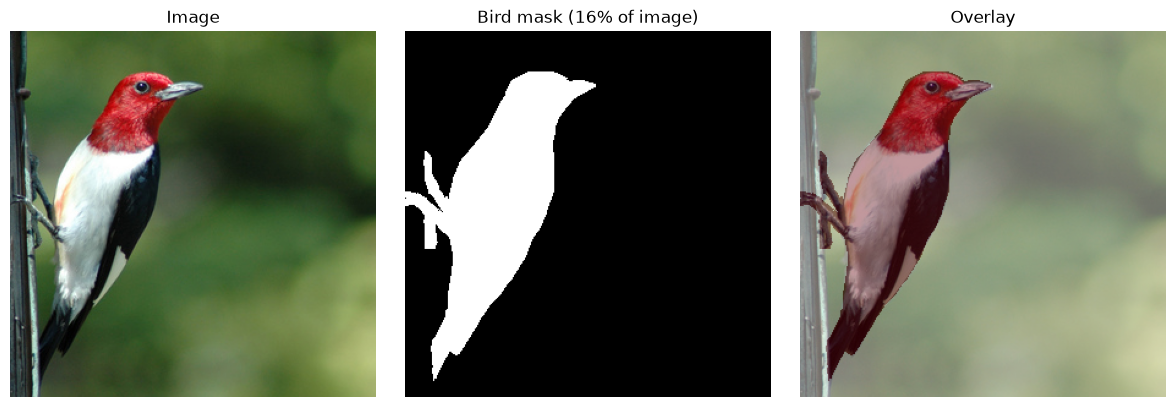

Extracting global explanation:  19%|█▉        | 1706/8940 [00:12<00:52, 136.71it/s]


seed 0 | 19.1% of image | 63% on bird


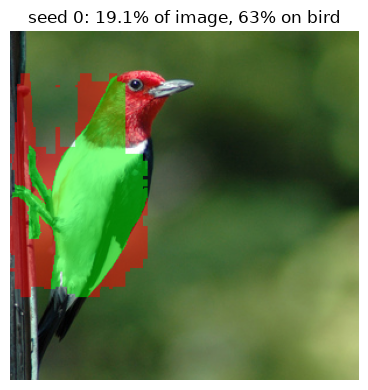

seed 0 | full  | 19.1% | 191.Red_headed_Woodpecker 0.902 | target 9.02e-01
seed 0 | green | 12.1% | 191.Red_headed_Woodpecker 0.788 | target 7.88e-01
seed 0 | red   | 7.0% | 186.Cedar_Waxwing 0.142 | target 6.91e-03

Just Bird Image
 Top: 191.Red_headed_Woodpecker 0.993 | target prob 9.93e-01

Remove Bird Image
 Top: 041.Scissor_tailed_Flycatcher 0.149 | target prob 3.81e-02

idx 2316 | true: 082.Ringed_Kingfisher | predicted: 082.Ringed_Kingfisher (0.857) | CORRECT


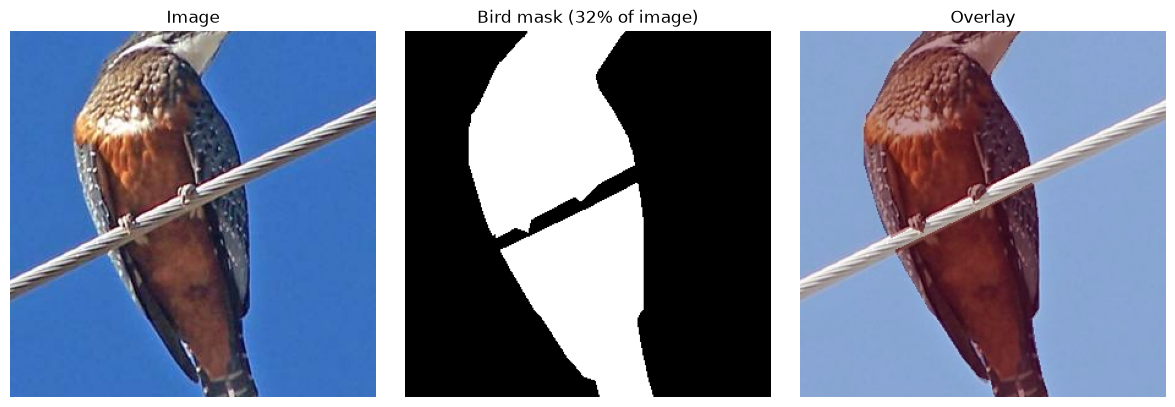

Extracting global explanation:  74%|███████▍  | 6601/8940 [00:48<00:17, 135.78it/s]


seed 0 | 73.8% of image | 40% on bird


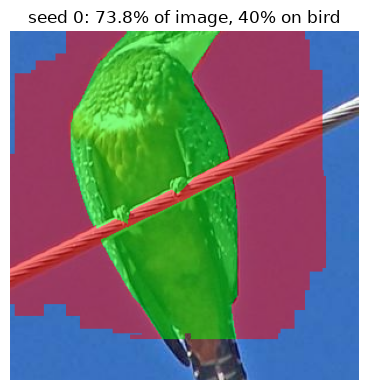

seed 0 | full  | 73.8% | 082.Ringed_Kingfisher 0.773 | target 7.73e-01
seed 0 | green | 29.9% | 082.Ringed_Kingfisher 0.935 | target 9.35e-01
seed 0 | red   | 44.0% | 078.Gray_Kingbird 0.492 | target 1.06e-03

Just Bird Image
 Top: 082.Ringed_Kingfisher 0.932 | target prob 9.32e-01

Remove Bird Image
 Top: 078.Gray_Kingbird 0.904 | target prob 3.51e-04



In [10]:
results = {}
for idx in [40, 3000, 1500, 5500, 2316]:
    results[idx] = run_image(idx, seeds=range(1))
